# Tarefa 1 — Construção e preparação do dataset AI vs. Human

Este notebook prepara um dataset em língua inglesa para a classificação binária de textos:

- `0 = Human` — texto escrito por uma pessoa;
- `1 = AI` — texto gerado por Inteligência Artificial.



In [1]:
# 1. Configuração e reprodutibilidade
import os
import re
import json
import hashlib
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

SEED = 42
DATASET_PATH = Path("AI_Human.csv")
OUTPUT_DIR = Path("tarefa1_output")
OUTPUT_DIR.mkdir(exist_ok=True)
MAX_TFIDF_FEATURES = 50000

random.seed(SEED)
np.random.seed(SEED)

print("Dataset:", DATASET_PATH)
print("Pasta de saída:", OUTPUT_DIR.resolve())

Dataset: AI_Human.csv
Pasta de saída: C:\Users\donex\OneDrive\Desktop\MEI\Módulos\Aprendizagem profunda\Moodle\aulas\class3-notebooks\Tarefa_1\tarefa1_output


## 1. Origem e descrição dos dados

Preencha os campos abaixo com informação verificável sobre o dataset utilizado. A descrição é necessária para que o grupo justifique a seleção dos dados no relatório.

In [2]:
DATASET_METADATA = {
    "name": "AI_Human.csv",
    "source_url": "PREENCHER_COM_URL_DA_FONTE_ORIGINAL",
    "provider_or_authors": "PREENCHER",
    "access_date": "PREENCHER",
    "license": "PREENCHER OU 'não identificada na fonte'",
    "language": "English",
    "task": "Binary classification: human-written vs AI-generated text",
    "label_definition": {"0": "Human", "1": "AI"},
    "selection_criteria": "PREENCHER",
    "known_limitations": "PREENCHER: temas, origem, distribuição, possível viés de geração, etc."
}
print(json.dumps(DATASET_METADATA, indent=2, ensure_ascii=False))

{
  "name": "AI_Human.csv",
  "source_url": "PREENCHER_COM_URL_DA_FONTE_ORIGINAL",
  "provider_or_authors": "PREENCHER",
  "access_date": "PREENCHER",
  "license": "PREENCHER OU 'não identificada na fonte'",
  "language": "English",
  "task": "Binary classification: human-written vs AI-generated text",
  "label_definition": {
    "0": "Human",
    "1": "AI"
  },
  "selection_criteria": "PREENCHER",
  "known_limitations": "PREENCHER: temas, origem, distribuição, possível viés de geração, etc."
}


In [3]:
# 2. Leitura e validação do formato
if not DATASET_PATH.exists():
    raise FileNotFoundError(f"Ficheiro não encontrado: {DATASET_PATH.resolve()}")

df_raw = pd.read_csv(DATASET_PATH)
print("Dimensão original:", df_raw.shape)
print("Colunas:", list(df_raw.columns))

text_candidates = [c for c in df_raw.columns if c.strip().lower() in {"text", "texto", "content"}]
label_candidates = [c for c in df_raw.columns if c.strip().lower() in {"generated", "label", "class", "target"}]
if not text_candidates or not label_candidates:
    raise ValueError("O CSV deve possuir uma coluna de texto e uma coluna de rótulo.")

TEXT_COL = text_candidates[0]
LABEL_COL = label_candidates[0]
print("Coluna de texto:", TEXT_COL)
print("Coluna de rótulo:", LABEL_COL)

Dimensão original: (487235, 2)
Colunas: ['text', 'generated']
Coluna de texto: text
Coluna de rótulo: generated


In [4]:
# 3. Normalização rigorosa dos rótulos
HUMAN_VALUES = {"0", "0.0", "false", "no", "n", "human", "humano", "real", "not generated"}
AI_VALUES = {"1", "1.0", "true", "yes", "y", "ai", "generated", "machine", "chatgpt", "gpt"}

def parse_label(value):
    v = str(value).strip().lower()
    if v in HUMAN_VALUES: return 0
    if v in AI_VALUES: return 1
    if "human" in v: return 0
    if any(k in v for k in ("ai", "gpt", "machine", "generated")): return 1
    raise ValueError(f"Rótulo não reconhecido: {value!r}")

df = pd.DataFrame({
    "text_raw": df_raw[TEXT_COL].astype("string"),
    "label": df_raw[LABEL_COL].map(parse_label).astype("int8")
})
print(df["label"].value_counts().sort_index())

label
0    305797
1    181438
Name: count, dtype: int64


## 2. Auditoria de qualidade

Esta secção identifica valores nulos, textos vazios, duplicados e conflitos de rótulos. A remoção de duplicados é feita antes da divisão, evitando que o mesmo texto apareça simultaneamente no treino e no teste.

In [5]:
# 4. Auditoria inicial
raw_audit = {
    "rows": int(len(df)),
    "null_text": int(df["text_raw"].isna().sum()),
    "empty_text": int((df["text_raw"].fillna("").str.strip() == "").sum()),
    "duplicate_rows": int(df.duplicated().sum()),
    "duplicate_texts": int(df["text_raw"].duplicated(keep=False).sum()),
    "invalid_labels": int((~df["label"].isin([0, 1])).sum())
}
print(json.dumps(raw_audit, indent=2))
print("\nDistribuição das classes:")
print(df["label"].value_counts().sort_index())

{
  "rows": 487235,
  "null_text": 0,
  "empty_text": 4,
  "duplicate_rows": 0,
  "duplicate_texts": 0,
  "invalid_labels": 0
}

Distribuição das classes:
label
0    305797
1    181438
Name: count, dtype: int64


In [6]:
# 5. Limpeza não destrutiva
# Mantemos pontuação, maiúsculas e contrações porque podem ser sinais úteis
# para deteção de autoria. A normalização é usada para consistência e deduplicação.
HTML_RE = re.compile(r"<[^>]*>")

def clean_text(text):
    text = "" if pd.isna(text) else str(text)
    text = text.replace("\\n", " ").replace("\\r", " ").replace("\\t", " ")
    text = HTML_RE.sub(" ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def canonical_text(text):
    return clean_text(text).casefold()

df["text"] = df["text_raw"].map(clean_text)
df["canonical_text"] = df["text"].map(canonical_text)
df["n_chars"] = df["text"].str.len().astype("int32")
df["n_words"] = df["text"].str.split().str.len().astype("int32")

before = len(df)
df = df[(df["text"] != "") & (df["label"].isin([0, 1]))].copy()
print("Removidos por texto vazio/rótulo inválido:", before - len(df))

Removidos por texto vazio/rótulo inválido: 4


In [7]:
# 6. Deteção de conflitos e duplicados
conflict_counts = df.groupby("canonical_text")["label"].nunique()
conflicting_texts = set(conflict_counts[conflict_counts > 1].index)
print("Textos com rótulos conflitantes:", len(conflicting_texts))

# Conflitos são removidos por serem ambíguos. Duplicados com o mesmo rótulo ficam apenas uma vez.
df = df[~df["canonical_text"].isin(conflicting_texts)].copy()
df = df.drop_duplicates(subset=["canonical_text"], keep="first").reset_index(drop=True)
print("Linhas após remoção de conflitos/duplicados:", len(df))
print("Duplicados restantes:", df["canonical_text"].duplicated().sum())

Textos com rótulos conflitantes: 5
Linhas após remoção de conflitos/duplicados: 464222
Duplicados restantes: 0


 label class_name  count  percentage
     0      Human 284462   61.277148
     1         AI 179760   38.722852

Estatísticas de comprimento:
        n_chars                                                          \
          count     mean      std   min     25%     50%     75%     max   
label                                                                     
0      284462.0  2353.06  1087.31  73.0  1535.0  2152.0  2922.0  9174.0   
1      179760.0  2127.69   783.13   1.0  1657.0  2049.0  2478.0  8831.0   

        n_words                                                     
          count    mean     std   min    25%    50%    75%     max  
label                                                               
0      284462.0  423.15  188.24  14.0  281.0  390.0  522.0  1668.0  
1      179760.0  345.68  116.54   1.0  275.0  338.0  404.0  1238.0  


C:\Users\donex\AppData\Local\Temp\ipykernel_21584\29037878.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["Human", "AI"])


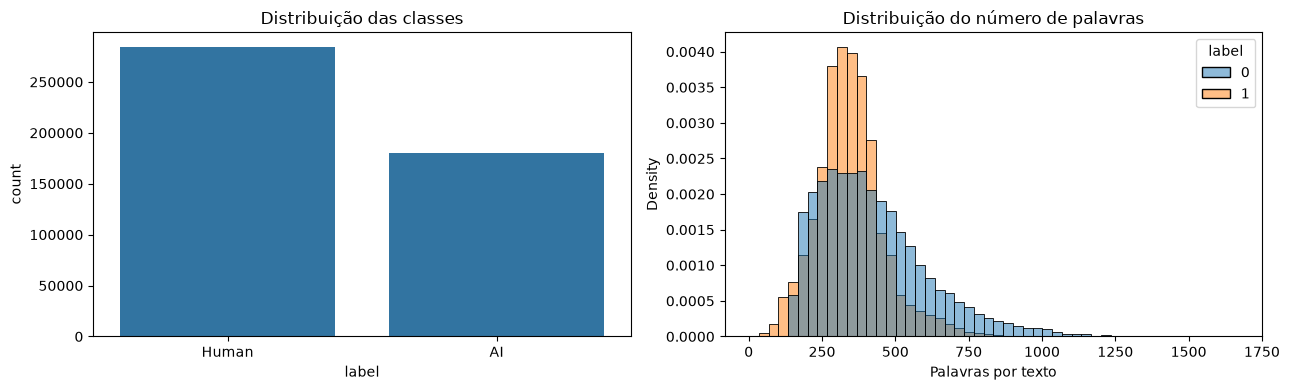

In [8]:
# 7. Estatísticas do dataset limpo
summary = pd.DataFrame({
    "label": [0, 1],
    "class_name": ["Human", "AI"],
    "count": [int((df.label == 0).sum()), int((df.label == 1).sum())]
})
summary["percentage"] = 100 * summary["count"] / len(df)
print(summary.to_string(index=False))
print("\nEstatísticas de comprimento:")
print(df.groupby("label")[["n_chars", "n_words"]].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x="label", ax=axes[0])
axes[0].set_xticklabels(["Human", "AI"])
axes[0].set_title("Distribuição das classes")
sns.histplot(data=df, x="n_words", hue="label", bins=50, stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Distribuição do número de palavras")
axes[1].set_xlabel("Palavras por texto")
plt.tight_layout()
plt.show()

## 3. Divisão estratificada e prevenção de fuga de informação

A divisão é feita em `70%` para treino, `15%` para validação e `15%` para teste. O parâmetro `stratify` preserva a proporção das classes. O TF-IDF é ajustado apenas no treino e aplicado posteriormente à validação e ao teste.

In [9]:
# 8. Divisão estratificada: treino / validação / teste
x = df["text"].reset_index(drop=True)
y = df["label"].reset_index(drop=True)

x_train, x_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.30, random_state=SEED, stratify=y
)
x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

split_summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "n_examples": [len(y_train), len(y_val), len(y_test)],
    "human": [(y_train == 0).sum(), (y_val == 0).sum(), (y_test == 0).sum()],
    "ai": [(y_train == 1).sum(), (y_val == 1).sum(), (y_test == 1).sum()]
})
for c in ["n_examples", "human", "ai"]: split_summary[c] = split_summary[c].astype(int)
split_summary["percentage"] = 100 * split_summary["n_examples"] / len(df)
print(split_summary.to_string(index=False))

     split  n_examples  human     ai  percentage
     train      324955 199123 125832   69.999914
validation       69633  42669  26964   14.999935
      test       69634  42670  26964   15.000151


In [10]:
# Verificação de sobreposição entre partições
train_hashes = set(x_train.map(canonical_text))
val_hashes = set(x_val.map(canonical_text))
test_hashes = set(x_test.map(canonical_text))
print("Sobreposição train/val:", len(train_hashes & val_hashes))
print("Sobreposição train/test:", len(train_hashes & test_hashes))
print("Sobreposição val/test:", len(val_hashes & test_hashes))
assert not (train_hashes & val_hashes)
assert not (train_hashes & test_hashes)
assert not (val_hashes & test_hashes)

Sobreposição train/val: 0
Sobreposição train/test: 0
Sobreposição val/test: 0


In [11]:
# 9. TF-IDF: fit apenas no treino
vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    min_df=2,
    max_features=MAX_TFIDF_FEATURES,
    sublinear_tf=True,
    norm="l2"
)
X_train = vectorizer.fit_transform(x_train)
X_val = vectorizer.transform(x_val)
X_test = vectorizer.transform(x_test)
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)
print("Vocabulário aprendido no treino:", len(vectorizer.vocabulary_))

X_train: (324955, 50000)
X_val: (69633, 50000)
X_test: (69634, 50000)
Vocabulário aprendido no treino: 50000


## 4. Exportação e documentação

Os ficheiros exportados nesta secção podem ser utilizados pelas tarefas seguintes. O `manifest.json` regista as principais decisões, dimensões e verificações do pipeline.

In [12]:
# 10. Exportar dataset limpo, partições e matrizes TF-IDF
from scipy.sparse import save_npz

export_df = df[["text", "label", "n_chars", "n_words"]].copy()
export_df.to_csv(OUTPUT_DIR / "AI_Human_clean.csv", index=False)
pd.DataFrame({"text": x_train, "label": y_train}).to_csv(OUTPUT_DIR / "train.csv", index=False)
pd.DataFrame({"text": x_val, "label": y_val}).to_csv(OUTPUT_DIR / "validation.csv", index=False)
pd.DataFrame({"text": x_test, "label": y_test}).to_csv(OUTPUT_DIR / "test.csv", index=False)
save_npz(OUTPUT_DIR / "X_train_tfidf.npz", X_train)
save_npz(OUTPUT_DIR / "X_validation_tfidf.npz", X_val)
save_npz(OUTPUT_DIR / "X_test_tfidf.npz", X_test)

import pickle
with open(OUTPUT_DIR / "tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(vectorizer, f)

manifest = {
    "seed": SEED,
    "source_metadata": DATASET_METADATA,
    "original_rows": raw_audit["rows"],
    "final_rows": int(len(df)),
    "class_distribution": {str(k): int(v) for k, v in df["label"].value_counts().sort_index().items()},
    "split_sizes": {row["split"]: int(row["n_examples"]) for _, row in split_summary.iterrows()},
    "tfidf": {"max_features": MAX_TFIDF_FEATURES, "ngram_range": [1, 2], "fit_on": "train only"},
    "cleaning": "HTML removal, whitespace normalization; punctuation/capitalization/contractions preserved",
    "duplicate_policy": "remove conflicting canonical texts and keep one copy of same-label duplicates",
    "files": [p.name for p in OUTPUT_DIR.iterdir()]
}
with open(OUTPUT_DIR / "manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False)

print("Ficheiros exportados:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(" -", p.name)

Ficheiros exportados:
 - AI_Human_clean.csv
 - manifest.json
 - test.csv
 - tfidf_vectorizer.pkl
 - train.csv
 - validation.csv
 - X_test_tfidf.npz
 - X_train_tfidf.npz
 - X_validation_tfidf.npz
